# GRU consumption carport





In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import time
# Gebruik de GPU als die er is, anders de CPU
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


# Data inladen

In [13]:
from pathlib import Path

#Projectmap zoeken, werkt vanuit elke submap
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
df= pd.read_parquet(ROOT / "prepared_data" / "forecast_targets_long.parquet")
carport_consumption = df[(df['location'] == 'carport') & (df['target_type'] == 'consumption')]
carport_consumption = carport_consumption.dropna(subset=['pow_imputed'])

## voorspel instellingen

In [14]:
stap_per_dag = 24 * 12               # 288 per dag

aantal_dagen_input = 7             # aantal dagen voor input
input_len = aantal_dagen_input * stap_per_dag

aantal_dagen_forecast = 3            # =aantal dagen voorspelling
horizon = aantal_dagen_forecast * stap_per_dag

stride = 12                          # het venster schuift 12 stappen (1 uur) per voorbeeld op

TIME_COL = 'timestamp'   # pas aan naar de naam van jouw tijdkolom (of gebruik de index, zie onder)
tijd = pd.to_datetime(carport_consumption[TIME_COL])
uur = tijd.dt.hour                                   # 0 t/m 23
dag_van_week = tijd.dt.dayofweek + uur / 24          # 0.0 t/m 6.96

carport_consumption['uur_sin']  = np.sin(2 * np.pi * uur / 24)
carport_consumption['uur_cos']  = np.cos(2 * np.pi * uur / 24)
carport_consumption['week_sin'] = np.sin(2 * np.pi * dag_van_week / 7)
carport_consumption['week_cos'] = np.cos(2 * np.pi * dag_van_week / 7)
TARGET_COL = 'pow_imputed'
FEATURE_COLS = ['pow_imputed', 'uur_sin', 'uur_cos', 'week_sin', 'week_cos']   # target blijft op index 0                  # features (inclusief target)

TRAIN_FRAC = 0.70                    # deel van de data voor training
VAL_FRAC = 0.15                      # deel voor validatie data  ,de rest is test data

In [15]:
n_features = len(FEATURE_COLS)
target_idx = FEATURE_COLS.index(TARGET_COL)

## chronologisch splisen

In [16]:
values = carport_consumption[FEATURE_COLS].values

n = len(values)
i_train = int(n * TRAIN_FRAC)
i_val = int(n * (TRAIN_FRAC + VAL_FRAC))

train_raw = values[:i_train]
val_raw = values[i_train:i_val]
test_raw = values[i_val:]

## normaliseren

In [17]:
train_mean = train_raw.mean(axis=0)
train_std = train_raw.std(axis=0)

train = (train_raw - train_mean) / train_std
val = (val_raw - train_mean) / train_std
test = (test_raw - train_mean) / train_std

In [18]:
class WindowDataset(Dataset):

    def __init__(self, data, input_len, horizon, target_idx, stride):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.input_len = input_len
        self.horizon = horizon
        self.target_idx = target_idx

        # Hoeveel vensters passen er in de data? Elk venster heeft input_len + horizon stappen nodig
        n_vensters = len(data) - input_len - horizon + 1
        self.starts = range(0, max(n_vensters, 0), stride)

    # Bereken het aantal voorbeelden
    def __len__(self):
        return len(self.starts)

    # Haal voorbeeld nummer idx op
    def __getitem__(self, idx):
        s = self.starts[idx]
        x = self.data[s : s + self.input_len]                                   # geschiedenis
        y = self.data[s + self.input_len : s + self.input_len + self.horizon,   # toekomst,
                      self.target_idx]                                          # alleen de target
        return x, y

Creeer dataset voor de training, validatie en test data.

In [19]:
train_dataset = WindowDataset(train, input_len, horizon, target_idx, stride)
val_dataset = WindowDataset(val, input_len, horizon, target_idx, stride)
test_dataset = WindowDataset(test, input_len, horizon, target_idx, stride)

print("aantal voorbeelden | train:", len(train_dataset), "| val:", len(val_dataset), "| test:", len(test_dataset))

aantal voorbeelden | train: 12379 | val: 2465 | test: 2465


Creeer DataLoader 

In [20]:
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

## model

## training loop


In [21]:
hidden_sizes = [64]            # het aantal getallen van hidden size staat gelijk aan het aantal lagen 
dropout = 0.2                  
learning_rate = 1e-3
output_size = horizon           

class Customgru(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, dropout=0.0):
        super().__init__()

        self.layers = nn.ModuleList()
        self.dropout = nn.Dropout(dropout)

        prev_size = input_size
        for h in hidden_sizes:
            self.layers.append(
                nn.GRU(input_size=prev_size,
                        hidden_size=h,
                        num_layers=1,
                        batch_first=True)
            )
            prev_size = h

        self.fc = nn.Linear(hidden_sizes[-1], output_size)

    def forward(self, x):
        out = x
        for lstm in self.layers:
            out, _ = lstm(out)
            out = self.dropout(out)

        out = out[:, -1, :]
        return self.fc(out)

model = Customgru(
    input_size=n_features,
    hidden_sizes=hidden_sizes,
    output_size=horizon,
    dropout=0.2
).to(DEVICE)

criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

print("CUSTOM gru |", sum(p.numel() for p in model.parameters()), "parameters")


CUSTOM gru | 69792 parameters


In [22]:
n_epochs = 20

train_loss_list = []
val_loss_list = []
epoch_time_list = []

std_target = train_std[target_idx]                    # standaarddeviatie van de target

if DEVICE == "cuda":
    torch.cuda.synchronize()
start_totaal = time.perf_counter()                    # start tijd

for epoch in range(n_epochs):
    start_epoch = time.perf_counter()
    # Trainen
    model.train()
    running_loss = 0.0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)

        optimizer.zero_grad()
        output = model(inputs)
        loss = criterion(output, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * targets.shape[0]

    train_loss = running_loss / len(train_dataset)
    train_loss_list.append(train_loss)

    # Validatie
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            loss = criterion(model(inputs), targets)
            val_loss += loss.item() * targets.shape[0]
    val_loss = val_loss / len(val_dataset)
    val_loss_list.append(val_loss)

    if DEVICE == "cuda":
        torch.cuda.synchronize()
    epoch_tijd = time.perf_counter() - start_epoch    # epoch train tijd berekenen
    epoch_time_list.append(epoch_tijd)

    print(f"Epoch {epoch+1}/{n_epochs}, train loss: {train_loss:.4f} (echte MAE: {train_loss * std_target:.1f}), validation loss: {val_loss:.4f} (echte MAE: {val_loss * std_target:.1f}) ")

totale_tijd = time.perf_counter() - start_totaal      # totale tijd berekenen
print(f"\nTotale trainingstijd: {totale_tijd:.1f}s ({totale_tijd/60:.1f} min)")
print(f"Gemiddeld per epoch: {np.mean(epoch_time_list):.1f}s")

Epoch 1/20, train loss: 0.5432 (echte MAE: 2045.1), validation loss: 0.4355 (echte MAE: 1639.4) 
Epoch 2/20, train loss: 0.5209 (echte MAE: 1960.9), validation loss: 0.4249 (echte MAE: 1599.5) 
Epoch 3/20, train loss: 0.5183 (echte MAE: 1951.1), validation loss: 0.4239 (echte MAE: 1595.8) 
Epoch 4/20, train loss: 0.5167 (echte MAE: 1945.4), validation loss: 0.4256 (echte MAE: 1602.4) 
Epoch 5/20, train loss: 0.5158 (echte MAE: 1941.7), validation loss: 0.4264 (echte MAE: 1605.2) 
Epoch 6/20, train loss: 0.5149 (echte MAE: 1938.3), validation loss: 0.4251 (echte MAE: 1600.4) 
Epoch 7/20, train loss: 0.5138 (echte MAE: 1934.4), validation loss: 0.4246 (echte MAE: 1598.5) 
Epoch 8/20, train loss: 0.5128 (echte MAE: 1930.6), validation loss: 0.4227 (echte MAE: 1591.2) 
Epoch 9/20, train loss: 0.5114 (echte MAE: 1925.4), validation loss: 0.4240 (echte MAE: 1596.4) 
Epoch 10/20, train loss: 0.5093 (echte MAE: 1917.2), validation loss: 0.4247 (echte MAE: 1598.8) 
Epoch 11/20, train loss: 0.50

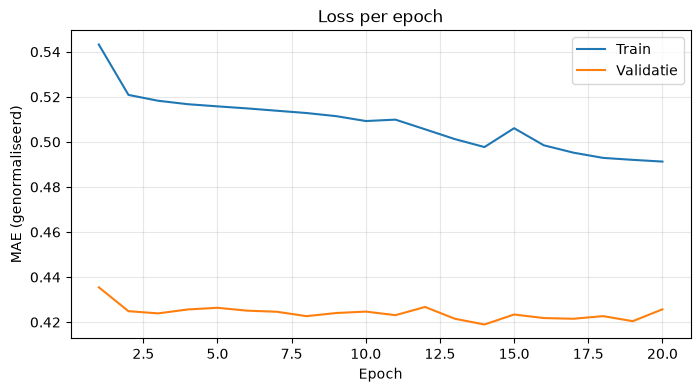

In [23]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_epochs + 1), train_loss_list, label='Train')
plt.plot(range(1, n_epochs + 1), val_loss_list, label='Validatie')
plt.xlabel('Epoch')
plt.ylabel('MAE (genormaliseerd)')
plt.title('Loss per epoch')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

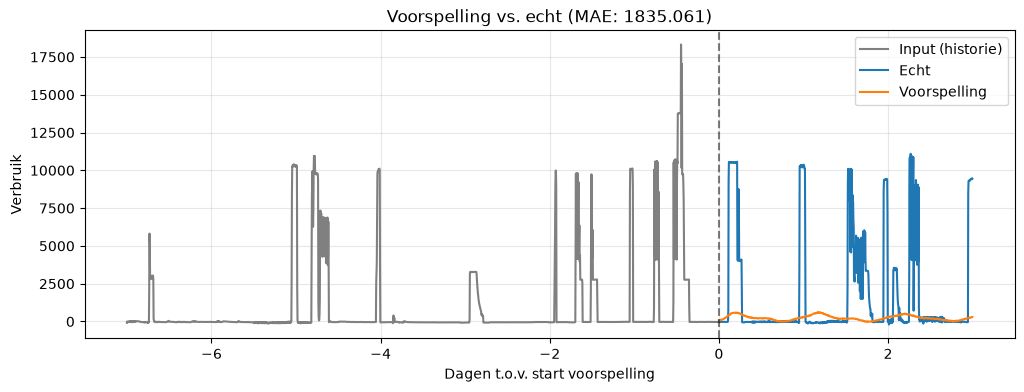

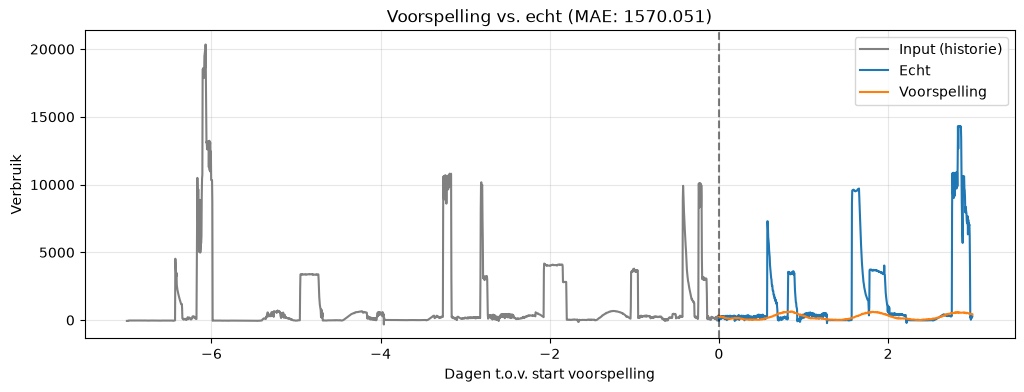

In [24]:
def plot_voorspelling(dataset, idx=0, titel='Voorspelling vs. echt'):
    model.eval()
    x, y = dataset[idx]
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(DEVICE)).cpu().numpy().flatten()

    # terug naar originele eenheid (de-normaliseren)
    m, s = train_mean[target_idx], train_std[target_idx]
    hist = x[:, target_idx].numpy() * s + m
    echt = y.numpy() * s + m
    pred = pred * s + m

    mae = np.abs(pred - echt).mean()

    t_hist = np.arange(-input_len, 0) / stap_per_dag     
    t_fc = np.arange(horizon) / stap_per_dag

    plt.figure(figsize=(12, 4))
    plt.plot(t_hist, hist, color='grey', label='Input (historie)')
    plt.plot(t_fc, echt, label='Echt')
    plt.plot(t_fc, pred, label='Voorspelling')
    plt.axvline(0, color='black', linestyle='--', alpha=0.5)
    plt.xlabel('Dagen t.o.v. start voorspelling')
    plt.ylabel('Verbruik')
    plt.title(f'{titel} (MAE: {mae:.3f})')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_voorspelling(test_dataset, idx=0)
plot_voorspelling(test_dataset, idx=len(test_dataset) // 2)   # een ander moment

MAE totaal: 1594 W
Dag 1: 1580 W
Dag 2: 1611 W
Dag 3: 1591 W


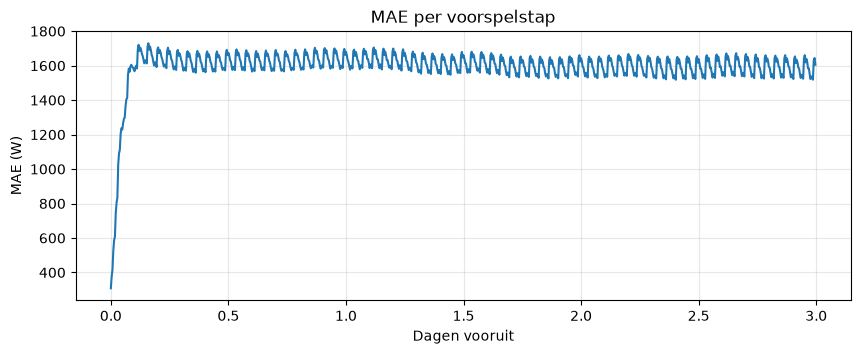

In [25]:
model.eval()
fouten = []
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        fouten.append((model(inputs) - targets).abs().cpu())
fouten = torch.cat(fouten).numpy() * std_target    

mae_per_stap = fouten.mean(axis=0)
print(f"MAE totaal: {fouten.mean():.0f} W")
for d in range(aantal_dagen_forecast):
    s = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
    print(f"Dag {d+1}: {mae_per_stap[s].mean():.0f} W")

plt.figure(figsize=(10, 3.5))
plt.plot(np.arange(horizon) / stap_per_dag, mae_per_stap)
plt.xlabel('Dagen vooruit')
plt.ylabel('MAE (W)')
plt.title('MAE per voorspelstap')
plt.grid(alpha=0.3)
plt.show()

## Resultaten opslaan
---
- Zelfde format als de andere modellen, opgeslagen in `models/results/`
- MAE in Watt op alle testvensters (elk uur een nieuwe forecast van 3 dagen)
- Persistence dag = zelfde tijdstip van de meest recente bekende dag, persistence week = zelfde tijdstip een week eerder

In [26]:
from pathlib import Path

MODEL_NAAM = "GRU"
NOTEBOOK = "gru_consumption_carport"
TARGET = "consumption"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
RESULTS_DIR = ROOT / "models" / "results"
MODEL_DIR = ROOT / "models" / "saved_models"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

#Voorspellen op alle testvensters, test_loader schudt niet dus de volgorde klopt
model.eval()
preds, targets_norm = [], []
if DEVICE == "cuda":
    torch.cuda.synchronize()
t0 = time.perf_counter()
with torch.no_grad():
    for inputs, targets in test_loader:
        preds.append(model(inputs.to(DEVICE)).cpu())
        targets_norm.append(targets)
if DEVICE == "cuda":
    torch.cuda.synchronize()
voorspeltijd = time.perf_counter() - t0

m, s = train_mean[target_idx], train_std[target_idx]
pred_test = torch.cat(preds).numpy() * s + m

#Echte waarden en baselines direct uit de reeks in Watt
y_arr = carport_consumption[TARGET_COL].to_numpy()
test_origins = i_val + input_len + np.array(test_dataset.starts)
h = np.arange(horizon)
t = test_origins[:, None] + h[None, :]
echt_test = y_arr[t]
base_dag = y_arr[t - stap_per_dag * (h // stap_per_dag + 1)]
base_week = y_arr[t - 7 * stap_per_dag]                 #altijd een week terug, ook als input_len geen 7 dagen is
assert np.allclose(torch.cat(targets_norm).numpy() * s + m, echt_test, atol=1.0), "testvensters komen niet overeen"


def scores(pred, echt):
    fout = pred - echt
    res = {"MAE": np.abs(fout).mean(), "RMSE": np.sqrt((fout ** 2).mean())}
    for d in range(aantal_dagen_forecast):
        sl = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
        res[f"MAE dag {d+1}"] = np.abs(fout[:, sl]).mean()
    #Rolling validation: elke dag een nieuwe forecast
    dagelijks = slice(None, None, stap_per_dag // stride)
    res["rolling MAE"] = np.abs(fout[dagelijks]).mean(axis=1).mean()
    res["rolling RMSE"] = np.sqrt((fout[dagelijks] ** 2).mean(axis=1)).mean()
    return res

alle = {MODEL_NAAM: pred_test, "Persistence dag": base_dag, "Persistence week": base_week}
resultaten = pd.DataFrame({naam: scores(pred, echt_test) for naam, pred in alle.items()}).T
resultaten.loc[MODEL_NAAM, "trainingstijd (s)"] = totale_tijd
resultaten.loc[MODEL_NAAM, "voorspeltijd (s)"] = voorspeltijd
resultaten = resultaten.round(1)

#Model opslaan en bestandsgrootte meten
pad = MODEL_DIR / f"{NOTEBOOK}.pt"
torch.save(model.state_dict(), pad)
resultaten.loc[MODEL_NAAM, "modelgrootte (MB)"] = round(pad.stat().st_size / 1e6, 3)

KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
            "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)",
            "modelgrootte (MB)"]
tijden = pd.to_datetime(carport_consumption["timestamp"])
resultaten["notebook"] = NOTEBOOK
resultaten["locatie"] = "carport"
resultaten["target"] = TARGET
resultaten["resolutie"] = "5 min"
resultaten["testperiode"] = f"{tijden.iloc[i_val]:%Y-%m-%d} t/m {tijden.iloc[-1]:%Y-%m-%d}"
resultaten = resultaten.reindex(columns=KOLOMMEN)
resultaten.to_csv(RESULTS_DIR / f"{NOTEBOOK}.csv")
resultaten

,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
GRU,gru_consumption_carport,carport,consumption,5 min,2026-01-07 t/m 2026-09-02,1594.1,3414.4,1580.5,1610.8,1591.0,1589.9,3253.6,186.7,0.7,0.282
Persistence dag,gru_consumption_carport,carport,consumption,5 min,2026-01-07 t/m 2026-09-02,2395.3,4367.6,2362.0,2367.7,2456.3,2400.7,4210.9,NaN,NaN,NaN
Persistence week,gru_consumption_carport,carport,consumption,5 min,2026-01-07 t/m 2026-09-02,2358.9,4305.1,2361.6,2364.2,2350.8,2360.1,4222.1,NaN,NaN,NaN
